# PHYS690 - Lecture 12: Applications of Initial- and Boundary-Value Problems
## From charge density to fields and particle motion

Lectures 10 and 11 developed two complementary numerical workflows:

- an **initial-value problem (IVP)** advances a state from known initial conditions;
- a **boundary-value problem (BVP)** solves for values throughout a domain subject to boundary conditions.

Today combines them in one electrostatic workflow. We will construct a charge density, solve Poisson's equation for the potential, compute the electric field, and then integrate the trajectory of a test particle through that field.

The final activity introduces nearest-grid-point charge deposition. That is the particle-to-grid step that begins Assignment 3. This lecture is still not a full particle-in-cell simulation: the source charges remain prescribed and the test particle does not feed back into the field.

## Learning Goals

By the end of class you should be able to:

- identify the IVP and BVP pieces of a coupled physical workflow;
- reuse a sparse finite-difference Poisson solver with a new source term;
- compute $\mathbf E=-\nabla V$ and test the field with Gauss's law;
- interpolate a grid field to an off-grid particle position;
- formulate and solve a particle trajectory as a first-order IVP;
- deposit prescribed particle charge with nearest-grid-point weighting;
- use conservation, residual, and refinement checks to diagnose each stage;
- recognize which pieces transfer directly to Assignment 3.

Most of today's notebook time is devoted to the four in-class coding activities. Each activity produces an object used by the next stage, so run the notebook in order.

In [2]:
# Numerical arrays, tables, and plotting.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sparse matrix assembly and sparse direct solution of A u = b.
from scipy import sparse
from scipy.sparse import linalg as spla

# Adaptive IVP integration and interpolation of grid fields to particle positions.
from scipy.integrate import solve_ivp
from scipy.interpolate import RegularGridInterpolator

plt.rcParams.update({
    "figure.figsize": (7, 4.8),
    "axes.grid": True,
    "grid.alpha": 0.3,
})

## 1. One Workflow, Two Kinds of Differential Equation

The electrostatic field is determined by the charge density and boundary conditions:

$$
-\nabla^2 V(x,y)=\frac{\rho(x,y)}{\epsilon_0},
\qquad
V\big|_{\partial\Omega}=0.
$$

This is a **boundary-value problem**. The solution is the potential over the entire domain. Once $V$ is known,

$$
\mathbf E(x,y)=-\nabla V(x,y).
$$

A test particle with charge $q$ and mass $m$ obeys

$$
m\frac{d^2\mathbf r}{dt^2}=q\mathbf E(\mathbf r).
$$

As in Lecture 10, rewrite this second-order equation as a first-order system with state

$$
\mathbf s(t)=\begin{pmatrix}x(t) & y(t) & v_x(t) & v_y(t)\end{pmatrix}^T.
$$

Then

$$
\frac{d\mathbf s}{dt}
=
\begin{pmatrix}
v_x\\
v_y\\
(q/m)E_x(x,y)\\
(q/m)E_y(x,y)
\end{pmatrix}.
$$

This is an **initial-value problem**. The BVP produces the field; the IVP uses that field to advance the particle.

### Computational Pipeline and Diagnostics

Each arrow below introduces a place where numerical error or a programming mistake can enter:

$$
\rho(x,y)
\longrightarrow
A\mathbf u=\mathbf b
\longrightarrow
V(x,y)
\longrightarrow
\mathbf E(x,y)
\longrightarrow
\mathbf s(t).
$$

We will attach a diagnostic to each stage:

| Stage | Diagnostic question |
|---|---|
| source $\rho$ | Is total charge represented correctly? |
| sparse solve | Is $\|A\mathbf u-\mathbf b\|$ small? |
| potential $V$ | Are the boundary values satisfied? |
| field $\mathbf E$ | Does $\nabla\cdot\mathbf E\approx\rho/\epsilon_0$? |
| particle IVP | Is the result insensitive to tighter solver tolerances? |

This staged validation is the same research habit used in Lectures 10 and 11: test the numerical object produced at each step before building more physics on top of it.

## 2. Reusable Grounded Poisson Solver from Lecture 11

We use a square domain with grounded conducting walls, $V=0$ on all four boundaries. The charge density is supplied as a two-dimensional array `rho[j, i]`.

At each interior grid point, the five-point finite-difference stencil gives one row of

$$
A\mathbf u=\mathbf b,
$$

where $\mathbf u$ contains only the interior potential values. Because every boundary value is zero, the boundary contributions to $\mathbf b$ vanish for this example.

The implementation is completed so today's activities can focus on applying and diagnosing the solver. Read the comments and connect each block to the matrix assembly developed in Lecture 11.

In [ ]:
# Dimensionless domain and permittivity used throughout the lecture.
Lx = 1.0
Ly = 1.0
eps0 = 1.0


def make_grid(nx, ny, Lx=Lx, Ly=Ly):
    '''Return coordinate arrays for a rectangular nx by ny node grid.'''
    x = np.linspace(0.0, Lx, nx)
    y = np.linspace(0.0, Ly, ny)
    X, Y = np.meshgrid(x, y, indexing="xy")
    return x, y, X, Y


def interior_index(i, j, nx):
    '''Map interior grid index (i,j) to one index in the vector u.'''
    # Boundary nodes are omitted, so each interior row contains nx-2 unknowns.
    return (j - 1) * (nx - 2) + (i - 1)


def build_grounded_poisson_system(rho, Lx=Lx, Ly=Ly, eps0=eps0):
    '''Build sparse A and b for -laplacian(V)=rho/eps0 and V=0 on the edge.'''
    rho = np.asarray(rho, dtype=float)
    if rho.ndim != 2 or min(rho.shape) < 3:
        raise ValueError("rho must be a 2D array with at least 3 nodes per axis")

    ny, nx = rho.shape
    dx = Lx / (nx - 1)
    dy = Ly / (ny - 1)
    n_unknown = (nx - 2) * (ny - 2)

    # LIL format supports efficient row-by-row insertion during assembly.
    A = sparse.lil_matrix((n_unknown, n_unknown), dtype=float)
    b = np.zeros(n_unknown, dtype=float)

    for j in range(1, ny - 1):
        for i in range(1, nx - 1):
            row = interior_index(i, j, nx)

            # Center coefficient and source term for this grid point.
            A[row, row] = 2.0 / dx**2 + 2.0 / dy**2
            b[row] = rho[j, i] / eps0

            # Add a matrix entry only when the neighbor is another unknown.
            # Grounded boundary neighbors have known value zero, so their RHS
            # contribution is also zero and does not need to be added.
            if i > 1:
                A[row, interior_index(i - 1, j, nx)] = -1.0 / dx**2
            if i < nx - 2:
                A[row, interior_index(i + 1, j, nx)] = -1.0 / dx**2
            if j > 1:
                A[row, interior_index(i, j - 1, nx)] = -1.0 / dy**2
            if j < ny - 2:
                A[row, interior_index(i, j + 1, nx)] = -1.0 / dy**2

    # CSR is efficient for arithmetic and sparse factorization/solution.
    return A.tocsr(), b, dx, dy


def solve_grounded_poisson(rho, Lx=Lx, Ly=Ly, eps0=eps0):
    '''Solve the grounded Poisson problem and return a result dictionary.'''
    A, b, dx, dy = build_grounded_poisson_system(rho, Lx=Lx, Ly=Ly, eps0=eps0)

    # spsolve returns the one-dimensional vector of interior potentials.
    u = spla.spsolve(A, b)

    # Reconstruct the full grid. Its zero-valued edge enforces grounded walls.
    V = np.zeros_like(rho, dtype=float)
    V[1:-1, 1:-1] = u.reshape((rho.shape[0] - 2, rho.shape[1] - 2))

    residual = A @ u - b
    return {
        "V": V,
        "A": A,
        "b": b,
        "u": u,
        "dx": dx,
        "dy": dy,
        "residual_norm": np.linalg.norm(residual),
        "relative_residual": np.linalg.norm(residual) / max(np.linalg.norm(b), 1.0),
    }

## In-Class Activity 1 - Solve a Smooth-Source BVP (12 Minutes)

Before representing charge with particles, start with a smooth charge density that can be sampled directly on the grid. Use a positive Gaussian cloud and a negative Gaussian cloud,

$$
\rho(x,y)=\rho_0 e^{-[(x-x_+)^2+(y-y_+)^2]/(2\sigma^2)}
-\rho_0 e^{-[(x-x_-)^2+(y-y_-)^2]/(2\sigma^2)}.
$$

Complete the function and solve cells below. Check the integrated charge before trusting the field solution.

In [ ]:
def gaussian_cloud(X, Y, x0, y0, sigma, amplitude):
    '''Return one 2D Gaussian charge cloud sampled on the grid.'''
    radius_squared = (X - x0)**2 + (Y - y0)**2

    # TODO: Return amplitude * exp[-r^2/(2 sigma^2)].
    return ...


# Use an odd number of points so the domain center lies on a grid node.
nx = ny = 65
x, y, X, Y = make_grid(nx, ny)

# Create a dipole-like smooth source from two opposite Gaussian clouds.
# Suggested centers: (0.35, 0.50) and (0.65, 0.50), sigma=0.07.
rho_smooth = gaussian_cloud(X, Y, 0.35, 0.50, 0.07, 1.0) - gaussian_cloud(X, Y, 0.65, 0.50, 0.07, 1.0)

# Integrate rho over the grid as a source diagnostic.
dx = x[1] - x[0]
dy = y[1] - y[0]
total_charge_smooth = np.sum(rho_smooth) * dx * dy
print(f"Integrated smooth charge = {total_charge_smooth:.3e}")

# TODO: Solve the grounded Poisson BVP and report the relative residual.
smooth_solution = solve_grounded_poisson(rho_smooth, Lx=Lx, Ly=Ly, eps0=eps0)
V_smooth = smooth_solution["V"]
print(f"Relative algebraic residual = {smooth_solution['relative_residual']:.3e}")

In [ ]:
# Plot rho_smooth and V_smooth side by side with labeled colorbars.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

# Example of plotting two 2D charge density array on the left with a colorbars.
plt1 = axes[0].imshow(rho_smooth, extent=(0, Lx, 0, Ly), origin='lower', cmap='seismic')
axes[0].set_title('Smooth Charge Density $\u03C1_{smooth}$')
plt.colorbar(plt1, ax=axes[0], label='Charge Density')

# TODO: Plot the potential V_smooth on the right with a colorbar.

plt.show()

### Checkpoint

Before continuing, verify that:

- the positive and negative clouds are visible in `rho_smooth`;
- their integrated charges nearly cancel;
- the potential is zero along all four edges;
- the algebraic residual is close to machine precision.

A tiny residual means the discrete linear system was solved accurately. It does not by itself establish that the grid is sufficiently fine.

## 3. From Potential to Electric Field

Lecture 11 computed the field from

$$
E_x=-\frac{\partial V}{\partial x},
\qquad
E_y=-\frac{\partial V}{\partial y}.
$$

NumPy arrays use axis order `[j, i]`, so axis 0 corresponds to $y$ and axis 1 corresponds to $x$. Therefore

```python
dV_dy, dV_dx = np.gradient(V, dy, dx)
```

returns derivatives in the correct array-axis order.

We can also test the computed field with Gauss's law,

$$
\nabla\cdot\mathbf E=\frac{\rho}{\epsilon_0}.
$$

Because taking numerical derivatives introduces additional truncation error, this check will not be as close to machine precision as the algebraic residual.

## In-Class Activity 2 - Compute and Validate the Field (10 Minutes)

Complete `compute_electric_field`, calculate the divergence of the field, and compare it with the source. Exclude the outermost grid nodes from the scalar error because one-sided boundary derivatives behave differently from centered interior derivatives.

In [ ]:
def compute_electric_field(V, dx, dy):
    '''Return Ex and Ey from a potential array V[j,i].'''
    # TODO: Compute dV/dy and dV/dx with np.gradient.
    dV_dy, dV_dx = ...

    # TODO: Apply E = -grad(V).
    Ex = ...
    Ey = ...
    return Ex, Ey


# TODO: Compute the electric field for the smooth-source potential.
Ex_smooth, Ey_smooth = ...

# Compute div(E) using the same axis-order convention.
dEy_dy, _ = np.gradient(Ey_smooth, dy, dx, edge_order=2)
_, dEx_dx = np.gradient(Ex_smooth, dy, dx, edge_order=2)
div_E = dEx_dx + dEy_dy

# Compare Gauss's law on interior nodes only.
gauss_error = div_E[1:-1, 1:-1] - rho_smooth[1:-1, 1:-1] / eps0
print(f"Gauss-law RMS error = {np.sqrt(np.mean(gauss_error**2)):.3e}")

In [ ]:
# TODO: Plot potential contours with electric-field streamlines (refer to lecture 11 notebook for an example).
fig, ax = plt.subplots(figsize=(6.5, 5.2))
...
ax.set(xlabel="x", ylabel="y", title="Smooth-source potential and electric field", aspect="equal")
plt.show()

## 4. Interpolate the Grid Field to a Particle

The electric field is known only at grid nodes, while a particle usually lies between nodes. A PIC-style calculation therefore needs a grid-to-particle interpolation step.

`RegularGridInterpolator` treats the grid as axes `(y, x)` because the field arrays are indexed as `[j, i]`. A physical point $(x_p,y_p)$ must therefore be passed to the interpolator in the order `(y_p, x_p)`.

Here we use bilinear interpolation. This is the field-to-particle counterpart of the particle-to-grid weighting introduced later in the lecture.

In [ ]:
# Build interpolators once; solve_ivp will call them many times.
Ex_interpolator = RegularGridInterpolator(
    (y, x), Ex_smooth, method="linear", bounds_error=True
)
Ey_interpolator = RegularGridInterpolator(
    (y, x), Ey_smooth, method="linear", bounds_error=True
)


def field_at_position(x, y):
    '''Interpolate Ex and Ey at one off-grid physical position.'''
    # Interpolator coordinates follow array-axis order: (y, x).
    point_yx = np.array([[y, x]])
    Ex_value = float(Ex_interpolator(point_yx)[0])
    Ey_value = float(Ey_interpolator(point_yx)[0])
    return Ex_value, Ey_value


# Sanity check: evaluate the field at the center of the domain.
print("E at domain center:", field_at_position(0.5, 0.5))

## In-Class Activity 3 - Integrate a Test-Particle IVP (15 Minutes)

Use the interpolated field in the first-order state equation

$$
\frac{d}{dt}(x,y,v_x,v_y)
=
\left(v_x,v_y,\frac{q}{m}E_x,\frac{q}{m}E_y\right).
$$

The parameter `charge_to_mass` is the charge-to-mass ratio $q/m$. It sets the
strength and sign of the electric acceleration,

$$
\mathbf a = \frac{q}{m}\mathbf E.
$$

This is a **test particle**: it responds to the electric field but does not
contribute to, or modify, the field. In particular, it is different from the
two Gaussian charge blobs used earlier to construct `rho_smooth`; those blobs
are fixed source distributions that generate the field, while this particle
moves through that precomputed field. Complete the right-hand side and call
`solve_ivp`.

In [ ]:
charge_to_mass = 0.08


def test_particle_rhs(t, state):
    '''Return time derivatives for state=[x, y, vx, vy].'''
    x, y, vx, vy = state

    # TODO: Interpolate the grid field at the current particle position.
    Ex_particle, Ey_particle = ...

    # TODO: Return [dx/dt, dy/dt, dvx/dt, dvy/dt].
    return np.array([...])


# Start above the center with a small transverse velocity.
state0 = np.array([0.50, 0.70, 0.08, 0.00])
t_span = (0.0, 3.0)
t_eval = np.linspace(*t_span, 400)

# TODO: Integrate with solve_ivp using method="RK45", rtol=1e-8, atol=1e-10.
trajectory = ...

print("solve_ivp success:", trajectory.success)
print("function evaluations:", trajectory.nfev)

In [ ]:
# TODO: Overlay the particle trajectory on the potential contours.
fig, ax = plt.subplots(figsize=(6.5, 5.2))
...
ax.set(xlabel="x", ylabel="y", title="Test-particle IVP in the electrostatic BVP field", aspect="equal")
plt.show()

In [ ]:
# TODO: Repeat the solve with rtol=1e-10 and atol=1e-12.
trajectory_tight = ...

# Compare the final state vectors as a tolerance-sensitivity diagnostic.
final_state_change = np.linalg.norm(trajectory.y[:, -1] - trajectory_tight.y[:, -1])
print(f"Final-state change after tightening tolerances = {final_state_change:.3e}")

### IVP/BVP Reflection

The field solve and particle solve have different numerical controls:

- the BVP accuracy is studied by refining $\Delta x$ and $\Delta y$;
- the IVP accuracy is studied by tightening `rtol` and `atol` or comparing time-integration methods.

## 5. Assignment 3 Bridge: Particles Become a Grid Source

So far, `rho_smooth` was defined by a continuous function. Assignment 3 instead starts with macroparticles stored in a pandas `DataFrame`. A deposition rule turns particle charges into the grid array $\rho_{j,i}$.

For nearest-grid-point (NGP) deposition, each particle is assigned to the nearest node:

$$
i=\operatorname{round}(x_p/\Delta x),
\qquad
j=\operatorname{round}(y_p/\Delta y).
$$

The grid stores charge density, so deposited charge is divided by the cell area:

$$
\rho_{j,i}\mathrel{+}=\frac{q_p}{\Delta x\Delta y}.
$$

The first diagnostic is charge conservation:

$$
\sum_{i,j}\rho_{j,i}\Delta x\Delta y
\stackrel{?}{=}
\sum_p q_p.
$$

NGP is intentionally simple and produces a blocky source. Assignment 3 asks you to compare it with cloud-in-cell (CIC), which distributes charge to four neighboring nodes.

NameError: name 'Lx' is not defined

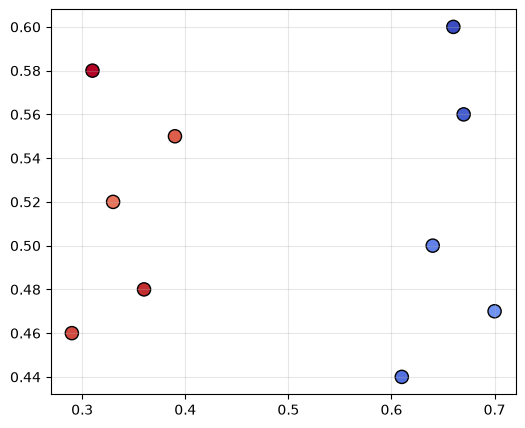

In [3]:
# A prescribed, reproducible set of positive and negative macroparticles.
particles = pd.DataFrame({
    "x": [0.29, 0.33, 0.36, 0.39, 0.31, 0.61, 0.64, 0.67, 0.70, 0.66],
    "y": [0.46, 0.52, 0.48, 0.55, 0.58, 0.44, 0.50, 0.56, 0.47, 0.60],
    "q": [1.0, 0.8, 1.1, 0.9, 1.2, -1.0, -0.9, -1.1, -0.8, -1.2],
})

fig, ax = plt.subplots(figsize=(6, 5))
scatter = ax.scatter(
    particles["x"],
    particles["y"],
    c=particles["q"],
    s=90,
    cmap="coolwarm",
    vmin=-particles["q"].abs().max(),
    vmax=particles["q"].abs().max(),
    edgecolor="black",
)
ax.set(xlim=(0, Lx), ylim=(0, Ly), xlabel="x", ylabel="y", title="Prescribed macroparticles", aspect="equal")
fig.colorbar(scatter, ax=ax, label="particle charge q")
plt.show()

## In-Class Activity 4 - Implement NGP Deposition (12 Minutes)

Complete the deposition function, check total charge, and reuse the Poisson solver on the deposited source. This practices the exact interface used in Assignment 3 without implementing the assignment's CIC comparison.

In [ ]:
def deposit_ngp(particles, nx, ny, Lx=Lx, Ly=Ly):
    '''Deposit particle charge to the nearest grid node as rho[j,i].'''
    dx = Lx / (nx - 1)
    dy = Ly / (ny - 1)
    rho = np.zeros((ny, nx), dtype=float)

    for particle in particles.itertuples(index=False):
        # Convert the physical position to nearest integer grid indices.
        i = int((particle.x + Lx/2) / dx)
        j = int((particle.y + Ly/2) / dy)

        # Keep roundoff from producing an index outside the grid.
        i = np.clip(i, 0, nx - 1)
        j = np.clip(j, 0, ny - 1)

        # TODO: Deposit charge density, not charge, at rho[j,i].
        ...

    return rho


# TODO: Deposit the particles on the same 65 by 65 grid.
rho_ngp = ...

particle_charge = particles["q"].sum()
deposited_charge = rho_ngp.sum() * dx * dy
print(f"Particle charge  = {particle_charge:.6f}")
print(f"Deposited charge = {deposited_charge:.6f}")
print(f"Charge difference = {deposited_charge - particle_charge:.3e}")

In [ ]:
# TODO: Solve for the NGP potential and compute its electric field.
ngp_solution = ...
V_ngp = ngp_solution["V"]
Ex_ngp, Ey_ngp = ...

# TODO: Plot rho_ngp and V_ngp side by side.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
...
plt.show()

### What Transfers Directly to Assignment 3?

You have now practiced the interfaces connecting the assignment stages:

```text
particles DataFrame
    -> deposit_ngp
    -> rho[j,i]
    -> solve_grounded_poisson
    -> V[j,i]
    -> compute_electric_field
    -> Ex[j,i], Ey[j,i]
```

Assignment 3 extends this workflow by asking you to:

- define your own physically motivated particle configuration;
- implement and compare both NGP and CIC deposition;
- compare at least two grid sizes or assignment schemes;
- summarize total charge, field magnitude, and field energy;
- reproduce the final analysis from a command-line Python script.

The test-particle trajectory from today's IVP activity is context for a full PIC loop, but it is not required in Assignment 3.

## 6. Common Failure Modes to Watch for in the Assignment

**Array-axis confusion**  
Grid fields use `rho[j, i]`, where `j` is the $y$ index and `i` is the $x$ index. Plotting and interpolation must use the same convention.

**Charge versus charge density**  
Depositing `q` directly gives charge per node. Poisson's equation needs charge density, so divide by $\Delta x\Delta y$.

**Boundary particles**  
Particles exactly on a boundary complicate CIC indexing. The assignment deliberately places particles strictly inside the domain.

**Residual mistaken for complete accuracy**  
A small $\|A\mathbf u-\mathbf b\|$ tests the algebraic solve. It does not test grid resolution or deposition error.

**Changing two numerical choices at once**  
When comparing NGP and CIC, hold the grid fixed. When comparing grid sizes, hold the deposition scheme and particle set fixed.

**Notebook-only state**  
The final command-line script must construct the particles, deposit charge, solve the field, and save outputs without depending on variables created in a notebook session.

## Takeaways

- IVPs and BVPs can be stages of the same physical workflow.
- A sparse Poisson solve maps a grid source $\rho$ to a grid potential $V$.
- Numerical differentiation maps $V$ to $\mathbf E$, adding another source of discretization error.
- Interpolation is required when particles do not sit exactly on grid nodes.
- `solve_ivp` can advance particle states through a field produced by a BVP solver.
- Particle deposition closes the particle-to-grid side of the PIC cycle.
- Diagnostics should accompany every interface, not only the final figure.

## Open-Source References and Further Reading

- SciPy `solve_ivp` documentation: https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html
- SciPy sparse linear algebra documentation: https://docs.scipy.org/doc/scipy/reference/sparse.linalg.html
- SciPy `RegularGridInterpolator` documentation: https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.RegularGridInterpolator.html
- WarpX PIC theory overview: https://warpx.readthedocs.io/en/latest/theory/intro.html
- Smilei PIC code documentation: https://smileipic.github.io/Smilei/
- Z. Donko et al., *eduPIC: an introductory particle based code for radio-frequency plasma simulation*: https://arxiv.org/abs/2103.09642